In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [9]:
df = pd.read_csv("single-node-xeone52697av4-C0-likwid-2-4-6-8-10.csv")

In [10]:
df.columns

Index(['ncells', 'ndofs', 'fe_degree', 'impl', 'threads', 'mpi_procs',
       'setup_time', 'assemble_time', 'solve_time', 'solver_iteration_time',
       'solver_iter_time_per_dof', 'iterations', 'mesh_str', 'L2_CPI',
       'L2_CPU_CLK_UNHALTED_CORE', 'L2_CPU_CLK_UNHALTED_REF', 'L2_Clock [MHz]',
       'L2_ICACHE_MISSES', 'L2_INSTR_RETIRED_ANY', 'L2_L1D_REPLACEMENT',
       'L2_L2 bandwidth [MBytes/s]', 'L2_L2 data volume [GBytes]',
       'L2_L2D evict bandwidth [MBytes/s]',
       'L2_L2D evict data volume [GBytes]', 'L2_L2D load bandwidth [MBytes/s]',
       'L2_L2D load data volume [GBytes]', 'L2_L2_TRANS_L1D_WB',
       'L2_RDTSC Runtime [s]', 'L2_Runtime (RDTSC) [s]',
       'L2_Runtime unhalted [s]', 'L2_call count', 'L3_CPI',
       'L3_CPU_CLK_UNHALTED_CORE', 'L3_CPU_CLK_UNHALTED_REF', 'L3_Clock [MHz]',
       'L3_INSTR_RETIRED_ANY', 'L3_L2_LINES_IN_ALL', 'L3_L2_TRANS_L2_WB',
       'L3_L3 bandwidth [MBytes/s]', 'L3_L3 data volume [GBytes]',
       'L3_L3 evict bandwidth [MB

In [11]:
DOFS = 'ndofs'
TIT = 'solver_iteration_time'

In [12]:
mb = df[df['impl'] == 'mb']
mf = df[df['impl'] == 'mf']

# Operational intensity

In [13]:
def plot_operational_intensity(df):
    for degree, local_df in df.groupby('fe_degree'):
        plt.semilogx(
            local_df[DOFS], local_df['MEM_DP_Operational intensity [FLOP/Byte]'],
            marker='o',
            label=degree
        )

    plt.legend()
    plt.show()

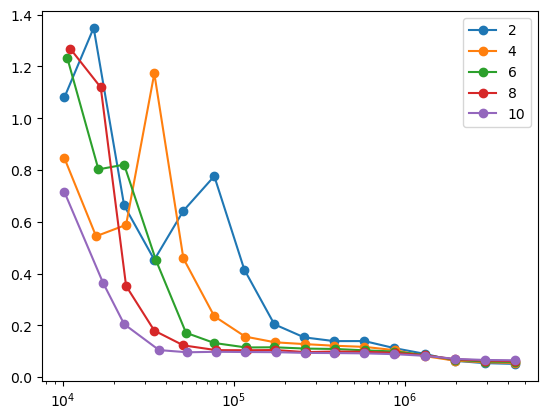

In [14]:
plot_operational_intensity(mb)

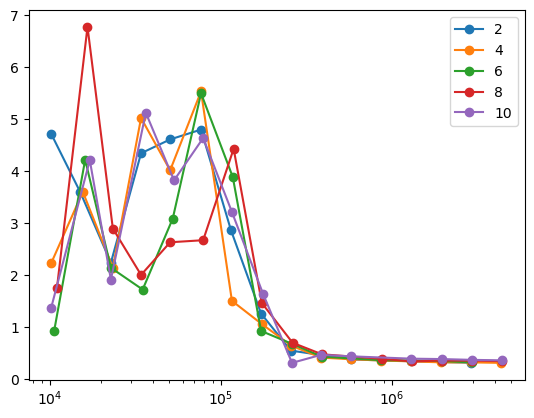

In [15]:
plot_operational_intensity(mf)

## General time per iteration

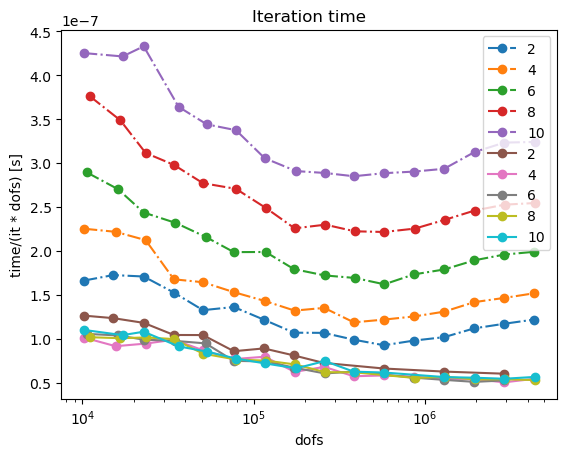

In [19]:
for impl, local_df in df.groupby('impl'):
    if impl == 'mb':
        style = '-.'
    else:
        style = '-'

    for degree, local_local_df in local_df.groupby('fe_degree'):
        plt.semilogx(
            local_local_df[DOFS], local_local_df['solver_iteration_time']/(local_local_df[DOFS]),
            marker='o',
            label=degree,
            linestyle=style
        )

plt.title('Iteration time')
plt.xlabel('dofs')
plt.ylabel('time/(it * dofs) [s]')
plt.legend()
plt.show()

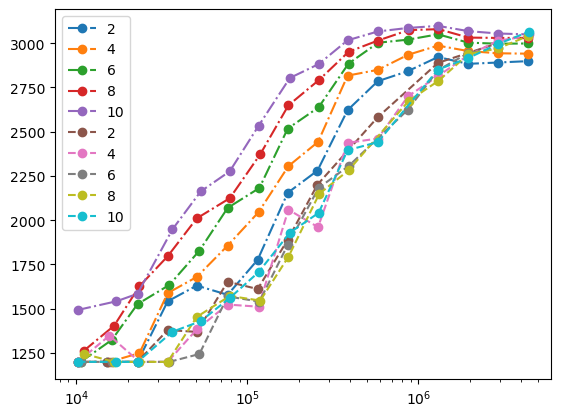

In [20]:
for impl, local_df in df.groupby('impl'):
    if impl == 'mb':
        style = '-.'
    else:
        style = '--'

    for degree, local_local_df in local_df.groupby('fe_degree'):
        plt.semilogx(
            local_local_df[DOFS], local_local_df['MEM_DP_Clock [MHz]'],
            marker='o',
            label=degree,
            linestyle=style
        )

plt.legend()
plt.show()

## Ram bandwidth

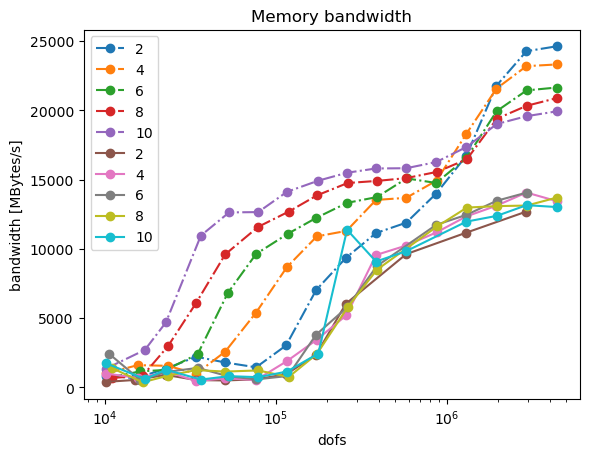

In [24]:
for impl, local_df in df.groupby('impl'):
    if impl == 'mb':
        style = '-.'
    else:
        style = '-'

    for degree, local_local_df in local_df.groupby('fe_degree'):
        plt.semilogx(
            local_local_df[DOFS], local_local_df['MEM_DP_Memory bandwidth [MBytes/s]'],
            marker='o',
            label=degree,
            linestyle=style
        )

plt.title('Memory bandwidth')
plt.xlabel('dofs')
plt.ylabel('bandwidth [MBytes/s]')
plt.legend()
plt.show()

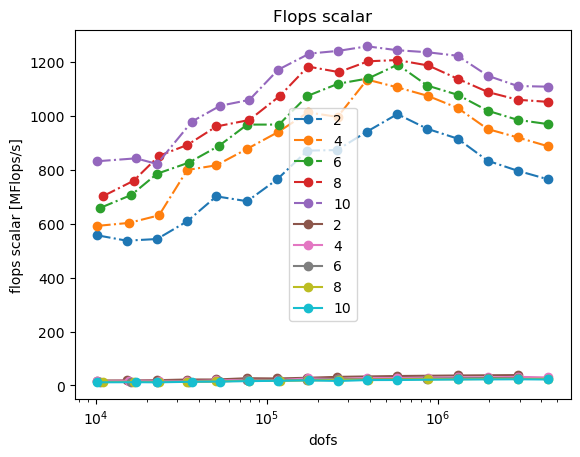

In [27]:
for impl, local_df in df.groupby('impl'):
    if impl == 'mb':
        style = '-.'
    else:
        style = '-'

    for degree, local_local_df in local_df.groupby('fe_degree'):
        plt.semilogx(
            local_local_df[DOFS], local_local_df['MEM_DP_Scalar [MUOPS/s]'],
            marker='o',
            label=degree,
            linestyle=style
        )

plt.title('Flops scalar')
plt.xlabel('dofs')
plt.ylabel('flops scalar [MFlops/s]')
plt.legend()
plt.show()

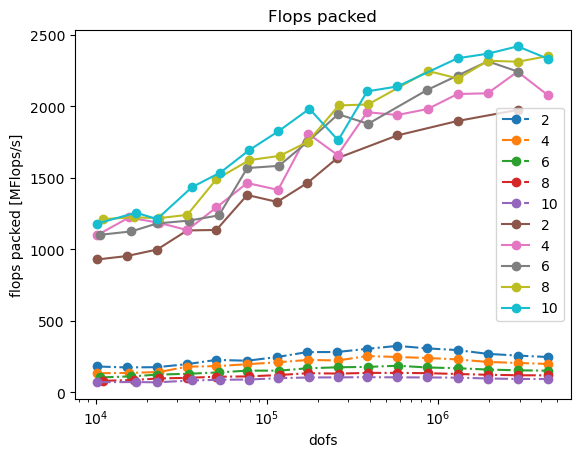

In [29]:
for impl, local_df in df.groupby('impl'):
    if impl == 'mb':
        style = '-.'
    else:
        style = '-'

    for degree, local_local_df in local_df.groupby('fe_degree'):
        plt.semilogx(
            local_local_df[DOFS], local_local_df['MEM_DP_Packed [MUOPS/s]'],
            marker='o',
            label=degree,
            linestyle=style
        )

plt.title('Flops packed')
plt.xlabel('dofs')
plt.ylabel('flops packed [MFlops/s]')
plt.legend()
plt.show()